# 01. Data profiling: what is wrong with the address file?

**Business question:** a healthtech operations team verifies patient mailing addresses by hand before kits,
letters and home-health visits go out. Before automating anything: how big is the file, which fields are
incomplete or inconsistent, and which kinds of problem dominate?

This notebook only looks at the raw records and the ZIP reference table. The planted ground truth is used once at
the end, to show the issue mix the later notebooks have to recover.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../reports/figures'
from reference import load_zip_reference
raw = pd.read_csv('../data/raw/address_records.csv', dtype=str, keep_default_na=False)
ref = load_zip_reference('../data/raw/zip_reference.csv')

In [2]:
print(f'{len(raw):,} address records, {raw.source_system.nunique()} source systems, '
      f'{raw.created_at.min()} to {raw.created_at.max()}')
print(f'reference table: {len(ref):,} ZIPs, {ref.groupby(["city", "state"]).ngroups:,} cities, {ref.state.nunique()} states')
raw.head(8)

49,920 address records, 4 source systems, 2025-01-01 00:11 to 2025-09-27 23:59
reference table: 3,170 ZIPs, 1,591 cities, 51 states


,record_id,first_name,last_name,address_line1,address_line2,city,state,zip,source_system,created_at
0,R044543,Maria,Harris,962 Hill Cir,Unit 21A,Linwood,MT,53787-9729,EHR_INTAKE,2025-09-09 01:36
1,R003643,Jose,Gonzalez,8482 Sycamore Pl,,Fairdale,NY,15238,PATIENT_PORTAL,2025-01-21 15:13
2,R015246,Hiro,Garcia,4214 laurel blvd,,Fox Falls,TX,76173,EHR_INTAKE,2025-03-29 04:10
3,R021404,Melissa,Kowalski,3207 Spruce Cir.,,Lakeford,WI,54987,EHR_INTAKE,2025-05-03 03:45
4,R048385,Omar,Young,po box 4833,,CARLWICK,SC,25980,EHR_INTAKE,2025-08-01 22:25
5,R040771,Ronald,Williams,4794 Cherry Rd,,Rivermont,KS,67492,CALL_CENTER,2025-08-19 00:29
6,R015472,Daniel,Gonzalez,1596 Harbor St,,Hawridge,CA,93635,PATIENT_PORTAL,2025-03-30 11:50
7,R039003,William,Harris,3659 Prospect Rd,,Silver Grove,AK,97232,EHR_INTAKE,2025-08-09 09:39


In [3]:
raw.source_system.value_counts().to_frame('records').assign(share=lambda d: (d.records / d.records.sum()).round(3))

,records,share
source_system,,
EHR_INTAKE,20076,0.402
PATIENT_PORTAL,15012,0.301
CALL_CENTER,9877,0.198
PARTNER_FEED,4955,0.099


## 1. Completeness
Empty strings count as missing.

In [4]:
fields = ['first_name', 'last_name', 'address_line1', 'address_line2', 'city', 'state', 'zip']
missing = (raw[fields].apply(lambda s: s.str.strip() == '')).mean().rename('missing share')
missing.to_frame().T.round(4)

,first_name,last_name,address_line1,address_line2,city,state,zip
missing share,0.0,0.0,0.0062,0.8356,0.0187,0.0095,0.029


`address_line2` is optional, so its blanks are expected. The other fields should always be present.

## 2. Format consistency
Checks on the raw text, before any cleaning.

In [5]:
import re
z = raw.zip.str.strip()
zip_pattern = np.select([z == '', z.str.fullmatch(r'\d{5}'), z.str.fullmatch(r'\d{5}-\d{4}'), z.str.fullmatch(r'\d{4}')],
                        ['missing', '5-digit', 'ZIP+4', '4-digit (lost leading zero)'], 'other')
pd.Series(zip_pattern).value_counts().to_frame('records')

,records
5-digit,46048
ZIP+4,2396
missing,1448
4-digit (lost leading zero),28


In [6]:
st = raw.state.str.strip()
state_pattern = np.select([st == '', st.str.fullmatch(r'[A-Z]{2}'), st.str.len() > 2], ['missing', '2-letter code', 'spelled out'], 'other')
print(pd.Series(state_pattern).value_counts().to_string())
print('\nexamples of non-code values:', st[st.str.len() > 2].unique()[:6])

2-letter code    48578
spelled out        869
missing            473

examples of non-code values: <StringArray>
['Michigan', 'California', 'Texas', 'Georgia', 'New York', 'Pennsylvania']
Length: 6, dtype: str


In [7]:
line1 = raw.address_line1.str.strip().str.upper()
last_tok = line1.str.replace('.', '', regex=False).str.split().str[-1].fillna('')
standard = {'ST', 'AVE', 'RD', 'DR', 'LN', 'CT', 'BLVD', 'PL', 'WAY', 'CIR'}
spelled = {'STREET', 'AVENUE', 'ROAD', 'DRIVE', 'LANE', 'COURT', 'BOULEVARD', 'PLACE', 'CIRCLE'}
cat = np.select([line1 == '', last_tok.isin(standard) & ~line1.str.contains(r'\.'), last_tok.isin(standard),
                 last_tok.isin(spelled)], ['missing', 'standard abbreviation', 'abbreviation with period', 'spelled out'], 'other ending')
pd.Series(cat).value_counts().to_frame('records')

,records
standard abbreviation,41085
other ending,5716
spelled out,1465
abbreviation with period,1346
missing,308


In [8]:
po = line1.str.contains(r'^(?:P\.?\s*O\.?|POST OFFICE|POB)\b', regex=True)
unit = line1.str.contains(r'(?:\bAPT\.?|\bUNIT\b|\bSTE\b|#)\s*\w+$', regex=True)
no_number = (line1 != '') & ~line1.str.match(r'^\d') & ~po
print(f'PO boxes: {po.sum():,}  (formats: {line1[po].str.extract(r"^(\D+?)\s*\d")[0].str.strip().value_counts().to_dict()})')
print(f'unit embedded in line 1: {unit.sum():,}   street line without house number: {no_number.sum():,}')
line1[unit].head(5).tolist()

PO boxes: 1,430  (formats: {'PO BOX': 482, 'P.O. BOX': 368, 'POST OFFICE BOX': 217, 'POB': 210, 'P O BOX': 153})
unit embedded in line 1: 2,794   street line without house number: 277


['9151 CHERRY CT UNIT 3',
 '5353 PINE ST, APT 8B',
 '2403 VALLEY AVE, APT. 31',
 '2343 PROSPECT PL APT. 3B',
 '3619 W SCHOOL COURT, APT 10B']

## 3. Agreement with the ZIP reference
A ZIP should exist, and its city and state should match the record.

In [9]:
zip5 = z.str[:5]
by_zip = ref.set_index('zip')
known = zip5.isin(by_zip.index)
ref_city = zip5.map(by_zip.city); ref_state = zip5.map(by_zip.state)
city_u = raw.city.str.strip().str.upper()
agreement = pd.Series({
    'ZIP present and 5+ digits': (zip5.str.len() == 5).sum(),
    'ZIP found in reference': known.sum(),
    'city matches ZIP': (known & (city_u == ref_city)).sum(),
    'state matches ZIP': (known & (st == ref_state)).sum(),
    'city and state match ZIP': (known & (city_u == ref_city) & (st == ref_state)).sum(),
})
agreement.to_frame('records').assign(share=lambda d: (d.records / len(raw)).round(4))

,records,share
ZIP present and 5+ digits,48444,0.9704
ZIP found in reference,47813,0.9578
city matches ZIP,43846,0.8783
state matches ZIP,45958,0.9206
city and state match ZIP,42181,0.8450


3,278 records whose city disagrees with the ZIP


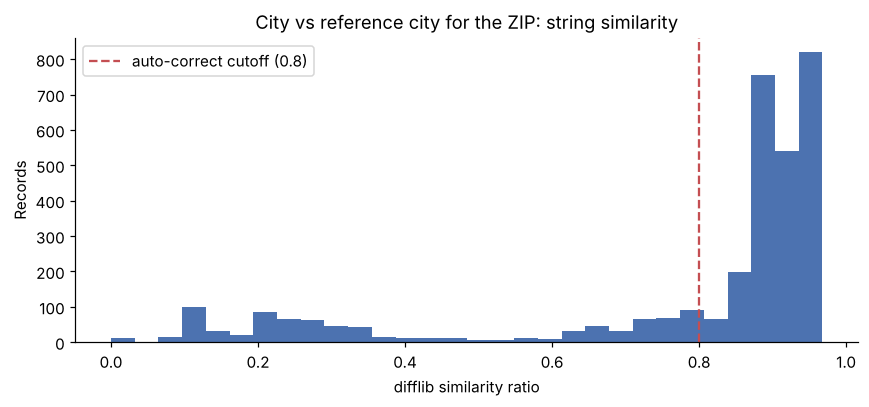

,city,state,zip,ref_city,similarity
5420,Redport,WA,97460-6138,HILLBURG,0.133333
27722,Marsh Grove,NE,62409,HAWFORD,0.222222
20533,Marshwood,DE,10351,STANBURY,0.235294
1927,Brwokgood,MO,63532,BROOKWOOD,0.777778
44102,Cedar pSrings,TN,37637,CEDAR SPRINGS,0.923077
30052,Haford,NE,62409,HAWFORD,0.923077
46833,Greeview,MI,44578,GREENVIEW,0.941176
9278,Stoneick,OH,44564,STONEWICK,0.941176


In [10]:
import difflib
mism = raw[known & (city_u != ref_city) & (city_u != '')].copy()
mism['ref_city'] = ref_city[mism.index]
mism['similarity'] = [difflib.SequenceMatcher(None, a.strip().upper(), b).ratio() for a, b in zip(mism.city, mism.ref_city)]
print(f'{len(mism):,} records whose city disagrees with the ZIP')
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(mism.similarity, bins=30, color='#4C72B0')
ax.axvline(0.8, color='#C44E52', ls='--', label='auto-correct cutoff (0.8)')
ax.set_title('City vs reference city for the ZIP: string similarity')
ax.set_xlabel('difflib similarity ratio'); ax.set_ylabel('Records'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/city_similarity.png', bbox_inches='tight'); plt.show()
mism[['city', 'state', 'zip', 'ref_city', 'similarity']].sample(8, random_state=1).sort_values('similarity')

Two populations: near-misses (typos, similarity above about 0.8) that a fuzzy match can fix, and genuinely
different cities (similarity below 0.6) where either the city or the ZIP is wrong and a person has to decide.

## 4. Duplicates

In [11]:
key = (raw.first_name.str.upper().str.strip() + '|' + raw.last_name.str.upper().str.strip() + '|'
       + line1.str.replace(r'\s+', ' ', regex=True) + '|' + zip5)
addr = line1.str.replace(r'\s+', ' ', regex=True) + '|' + zip5
print(f'exact repeats of name + street + ZIP (raw text): {key.duplicated().sum():,}')
print(f'records sharing a street + ZIP with another record: {addr.duplicated(keep=False).sum():,} '
      '(includes household members, who are not duplicates)')

exact repeats of name + street + ZIP (raw text): 1,440
records sharing a street + ZIP with another record: 5,530 (includes household members, who are not duplicates)


## 5. Summary of raw issue indicators

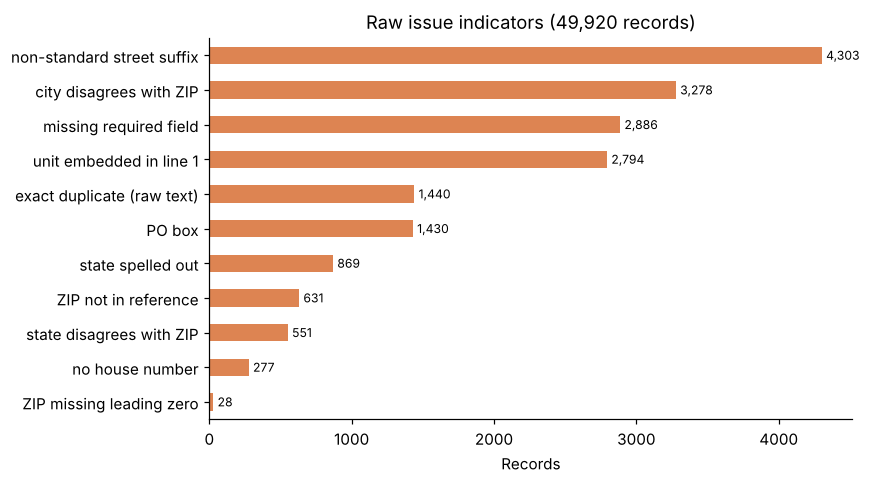

In [12]:
indicators = pd.Series({
    'missing required field': (raw[['address_line1', 'city', 'state', 'zip']].apply(lambda s: s.str.strip() == '')).any(axis=1).sum(),
    'non-standard street suffix': (pd.Series(cat).isin(['spelled out', 'abbreviation with period', 'other ending']) & ~po.values & ~unit.values).sum(),
    'unit embedded in line 1': unit.sum(),
    'PO box': po.sum(),
    'state spelled out': (pd.Series(state_pattern) == 'spelled out').sum(),
    'ZIP missing leading zero': (pd.Series(zip_pattern) == '4-digit (lost leading zero)').sum(),
    'ZIP not in reference': ((zip5.str.len() == 5) & ~known).sum(),
    'city disagrees with ZIP': len(mism),
    'state disagrees with ZIP': (known & (st != ref_state) & (st.str.len() == 2)).sum(),
    'no house number': no_number.sum(),
    'exact duplicate (raw text)': key.duplicated().sum(),
}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
indicators.plot.barh(ax=ax, color='#DD8452')
ax.set_title(f'Raw issue indicators ({len(raw):,} records)'); ax.set_xlabel('Records'); ax.set_ylabel('')
for i, v in enumerate(indicators):
    ax.text(v + 30, i, f'{v:,}', va='center', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/raw_issue_indicators.png', bbox_inches='tight'); plt.show()

### Planted issue mix (ground truth, for reference)
The generator records which problems it planted. The workflow never sees this file; it is used to score it in
notebook 02.

In [13]:
gt = pd.read_csv('../data/raw/address_ground_truth.csv', dtype=str, keep_default_na=False)
planted = gt.planted_issues.str.split('|').explode()
print(f'records with at least one planted issue: {(gt.planted_issues != "").mean():.1%}')
planted[planted != ''].value_counts().to_frame('records')

records with at least one planted issue: 34.6%


,records
planted_issues,
suffix_variant,4618
unit_in_line1,2805
city_typo_minor,2291
exact_duplicate,1440
po_box,1421
missing_zip,1204
state_spelled_out,869
zip_transposed,704
missing_city,689


## Findings

* The file has **49,920 records** from 4 source systems (January to September 2025); the reference table covers
  3,170 ZIPs and 1,591 cities in 50 states plus DC.
* Required fields are mostly present, but not always: ZIP is missing on 2.9% of records, city on 1.9%, state on
  0.95% and the street line on 0.6%.
* Formats are inconsistent: 2,396 ZIP+4 values and 28 four-digit ZIPs that lost a leading zero, 869 spelled-out
  states, 1,465 spelled-out street suffixes and 1,346 abbreviations with a period, 2,794 units embedded in line 1,
  and 1,430 PO boxes written five different ways.
* Only **84.5%** of records have a city and state that both agree with the ZIP. The 3,278 city disagreements are
  bimodal: most are near-misses with similarity above 0.8 (typos a fuzzy match can fix), the rest are genuinely
  different cities that need a decision.
* 1,440 records repeat an earlier name + street + ZIP exactly; 5,530 records share an address with another record,
  which includes household members who are not duplicates.
* Ground truth check: 34.6% of records carry at least one planted issue, led by suffix variants (4,618), embedded
  units (2,805) and minor city typos (2,291).